# Final full50k model review
Author / Kaggle team: **Zihan Xu**. Release: long111_full50k_v2, 2026-11-06.

## tl;dr
The accepted 30-run confirmation study selects long_111/TTA:96.04% research validation mean over 3 seeds. The final seed42 model uses all 50k images,240epochs,2,436,346parameters. **Final Kaggle accuracy is not available.** The previous raw model's user-reported score is 85%; it is a different model.

## Context & Methods
This executed notebook recomputes counts from all 30 runs' saved per-image predictions, verifies the 20 configuration/policy summaries, checks delivered CSVs and loads the exported weights. It does not retrain or claim access to hidden test labels.

### Key assumptions
Research seeds share the same 5k validation images, with repeated model selection on that split. Error bars below are seed SD, not confidence intervals. All 50k images are used in the final fit, so none of the previous local holdouts remains independent.


In [1]:
from pathlib import Path
import csv, hashlib, json, sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
TASK=Path.cwd()
if not (TASK/'evidence/config.json').exists():
    TASK=Path('tasks/2026-11-06_long111_full50k_v2').resolve()
sys.path.insert(0,str(TASK/'code'))
import operators
plt.rcParams.update({'font.size':10,'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False})
def read(p):return json.loads(p.read_text(encoding='utf-8-sig'))
def digest(p):return hashlib.sha256(p.read_bytes()).hexdigest()
config=read(TASK/'evidence/config.json')
history=pd.read_csv(TASK/'evidence/history.csv')
summary=pd.read_csv(TASK/'evidence/confirmation_inference_summary.csv')
metrics=pd.read_csv(TASK/'evidence/confirmation_inference_run_metrics.csv')
versions=read(TASK/'evidence/submission_versions.json')


## Data
Thirty research runs,20 aggregated configuration/policy results,240 full50k training epochs and4distinct CSV choices. Inputs are versioned evidence files; no raw images are embedded.

In [2]:
assert len(summary)==20 and len(metrics)==60
assert len(history)==240 and history.epoch.tolist()==list(range(1,241))
assert history.examples.eq(50000).all() and history.updates.eq(391).all()
for row in metrics.itertuples():
    filename='validation_predictions.csv' if row.policy=='raw' else 'tta_predictions.csv'
    frame=pd.read_csv(TASK/'evidence/research_logs'/f'{row.configuration}_seed{row.seed}'/filename)
    # Column names in the original evidence are inspected below.
    truth=frame['label'] if 'label' in frame else frame['true_label']
    prediction=frame['prediction'] if 'prediction' in frame else frame['predicted_label']
    assert len(frame)==5000 and int((truth==prediction).sum())==row.validation_correct
for row in summary.itertuples():
    subset=metrics[(metrics.configuration==row.configuration)&(metrics.policy==row.policy)]
    assert len(subset)==3 and int(subset.validation_correct.sum())==row.total_correct
    assert abs(row.mean_accuracy_percent-row.total_correct/15000*100)<1e-10
print('Verified all30 runs,60 prediction tables and20 means; shared5,000-image validation set.')
print('Final training:50,000 images x240epochs =',int(history.examples.sum()),'image presentations;',int(history.updates.sum()),'updates.')


Verified all30 runs,60 prediction tables and20 means; shared5,000-image validation set.
Final training:50,000 images x240epochs = 12000000 image presentations; 93840 updates.


## Results
### Model size and score provenance

In [3]:
torch.set_num_threads(4)
checkpoint=torch.load(TASK/'model.pt',map_location='cpu',weights_only=True)
model=operators.build(checkpoint['recipe']);model.load_state_dict(checkpoint['model_state'],strict=True)
parameters=sum(p.numel() for p in model.parameters())
assert parameters==2436346<=5000000
assert checkpoint['epoch']==240 and checkpoint['training_images']==50000
print('Final model trainable parameters:',parameters)
print('Final model independent test/Kaggle accuracy: NOT AVAILABLE (awaiting official score)')
print('Previous core_ep240/raw Kaggle accuracy:85.00%, user-reported; remote bytes unverified')
display(summary.pivot(index='configuration',columns='policy',values='mean_accuracy_percent').round(4))


Final model trainable parameters: 2436346
Final model independent test/Kaggle accuracy: NOT AVAILABLE (awaiting official score)
Previous core_ep240/raw Kaggle accuracy:85.00%, user-reported; remote bytes unverified


policy,raw,tta
configuration,,
confirm_000,94.8267,95.2333
confirm_001,95.0467,95.3867
confirm_010,95.0800,95.2400
confirm_011,94.9267,95.2667
confirm_100,95.1733,95.5267
confirm_101,95.3133,95.5333
confirm_110,95.2333,95.4667
confirm_111,95.4400,95.6600
long_000,95.4267,95.7333


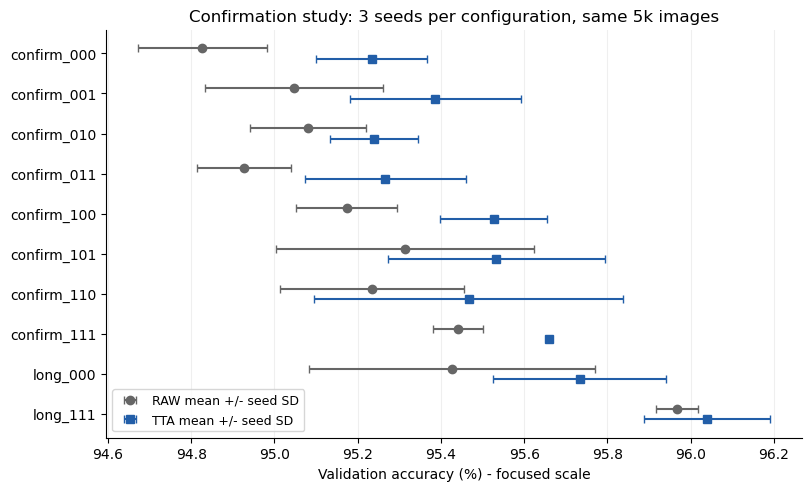

In [4]:
fig,ax=plt.subplots(figsize=(8,4.8),layout='constrained')
names=summary.configuration.drop_duplicates().tolist();y=np.arange(len(names))
for policy,offset,color,marker in [('raw',-.13,'#666666','o'),('tta',.13,'#225EA8','s')]:
    data=summary[summary.policy==policy].set_index('configuration').loc[names]
    ax.errorbar(data.mean_accuracy_percent,y+offset,xerr=data.sd_accuracy_pp,fmt=marker,color=color,capsize=3,label=policy.upper()+' mean +/- seed SD')
ax.set_yticks(y,names);ax.set_xlabel('Validation accuracy (%) - focused scale')
ax.set_title('Confirmation study: 3 seeds per configuration, same 5k images')
ax.invert_yaxis();ax.grid(axis='x',alpha=.2);ax.legend(loc='lower left',fontsize=9)
fig.savefig(TASK/'figures/confirmation.png',dpi=180);display(fig);plt.close(fig)


long_111/TTA ranks first among measured choices. Its gain over raw is0.0733percentage points, with an unadjusted paired95%t interval[-0.3962,0.5429]. No34-comparison Holm-adjusted result reaches0.05. This supports a practical ranking, not a guarantee of superior unseen accuracy.

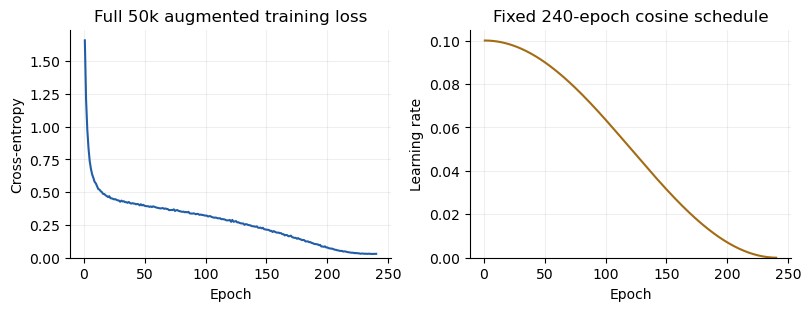

Last epoch augmented training accuracy: 99.274% (NOT independent test accuracy)


In [5]:
fig,axes=plt.subplots(1,2,figsize=(8,3),layout='constrained')
axes[0].plot(history.epoch,history.train_loss,color='#225EA8')
axes[0].set(xlabel='Epoch',ylabel='Cross-entropy',
            title='Full 50k augmented training loss',ylim=(0,None))
axes[1].plot(history.epoch,history.lr,color='#A36C14')
axes[1].set(xlabel='Epoch',ylabel='Learning rate',
            title='Fixed 240-epoch cosine schedule',ylim=(0,None))
for ax in axes:ax.grid(alpha=.2)
fig.savefig(TASK/'figures/training.png',dpi=180);display(fig);plt.close(fig)
print('Last epoch augmented training accuracy:',f'{history.train_accuracy.iloc[-1]*100:.3f}%','(NOT independent test accuracy)')


### Submission integrity
Different predictions are alternatives, not evidence that one is correct. Recommendation follows research selection and the requested full50k refit.

In [6]:
ids=None
for v in versions:
    path=TASK/'submissions'/v['version']/'submission.csv'
    frame=pd.read_csv(path)
    assert list(frame)==['id','label'] and len(frame)==frame.id.nunique()==2000
    assert pd.api.types.is_integer_dtype(frame.label) and frame.label.between(0,9).all()
    assert digest(path)==v['submission_sha256']
    if ids is None:ids=frame.id.tolist()
    else:assert ids==frame.id.tolist()
assert len({v['submission_sha256'] for v in versions})==4
display(pd.DataFrame(versions)[['version','configuration','training_images','policy','kaggle_score']])
print('All4CSV files valid; recommended:',versions[0]['version'])
print('Original CPU TTA replay:',read(TASK/'evidence/original_independent_replay.json')['labels_match_reference'])
display(pd.DataFrame(read(TASK/'evidence/submission_disagreements.json')))


,version,configuration,training_images,policy,kaggle_score
0,01_RECOMMENDED_full50k_tta,long_111,50000,tta,NaN
1,02_ALTERNATIVE_full50k_raw,long_111,50000,raw,NaN
2,03_previous_core240_flip,core_ep240,40000,tta,NaN
3,04_previous_core240_raw_score085,core_ep240,40000,raw,0.85


All4CSV files valid; recommended: 01_RECOMMENDED_full50k_tta
Original CPU TTA replay: True


,01_RECOMMENDED_full50k_tta,02_ALTERNATIVE_full50k_raw,03_previous_core240_flip,04_previous_core240_raw_score085
01_RECOMMENDED_full50k_tta,0,69,202,214
02_ALTERNATIVE_full50k_raw,69,0,204,218
03_previous_core240_flip,202,204,0,84
04_previous_core240_raw_score085,214,218,84,0


## Takeaways
Use 01_RECOMMENDED_full50k_tta first. The 02 raw alternative uses the same final weights with half the forward passes. Versions 03/04 preserve the previous model; only 04 has a user-reported Kaggle score. No test answers were manually labeled or changed.

The full50k fit is verified as a completed 240-epoch run. The research 96.04% mean is not its test accuracy. Actual generalization improvement awaits official scoring. Repeated holdout use, only 3 research seeds, and possible competition distribution differences remain limitations.

References and exact reproduction commands are in README.md and report.pdf. Architecture/operators match the executed source; the standalone training adapter removes only project-specific queue/data-discovery dependencies. Full retraining was not repeated during packaging.
